# Tuần 3 — Mạng nơ-ron nhiều lớp (MLP), quá khớp, so sánh công bằng và khóa quyết định
Thời lượng dự kiến: **4 giờ** (3 giờ notebook, 1 giờ viết nháp Mục 3.6–3.7 và Mục 4 của báo cáo)

**Mục tiêu.** Sau tuần này, sinh viên có thể:
1. giải thích MLP mở rộng hồi quy logistic như thế nào và tính tay lan truyền tiến của một MLP nhỏ;
2. nhận ra **quá khớp** (*overfitting*) qua đường cong hàm mất mát theo epoch trên train và validation, và giải thích cơ chế **dừng sớm**;
3. chọn **siêu tham số** (số nơ-ron ẩn) trên validation, có tính đến **dao động theo seed**;
4. so sánh các mô hình **công bằng**: mỗi mô hình dùng ngưỡng quyết định tốt nhất của chính nó;
5. phát biểu một **giả thuyết** trước khi thực nghiệm (E4), rồi chọn mô hình, ngưỡng và **khóa** lựa chọn trước khi dùng test.

**Cách dùng notebook.** Mỗi mục được đánh dấu bằng một nhãn:
`[KIẾN THỨC]` nội dung cần đọc · `[MINH HỌA]` ô mã có sẵn, chạy và quan sát kết quả ·
`[YÊU CẦU]` phần sinh viên thực hiện: thay mỗi chỗ `None` hoặc `____` bằng mã phù hợp ·
`[TỰ KIỂM TRA]` ô kiểm tra tự động, in **ĐẠT** khi kết quả đúng ·
`[BÁO CÁO]` ghi câu trả lời ngắn vào ô văn bản để đưa vào báo cáo ·
`[CÂU HỎI SUY NGẪM]` câu hỏi để sinh viên tự trả lời trước; gợi ý ở cuối notebook.

> **Sổ tay thư viện** (`00_so_tay_thu_vien.pdf`, phát kèm đồ án) — các mục cần tra cứu trong tuần này: mục 3 (vẽ hình); mục 6 (huấn luyện, dự đoán, ngưỡng); mục 7 (đánh giá mô hình); mục 10 (đọc thông báo lỗi). Mỗi mục có đoạn mã mẫu chạy trên chính dữ liệu của đồ án, kết quả in ra và các lỗi thường gặp.

## Thiết lập
`[MINH HỌA]` Ô dưới đây nạp thư viện, tải dữ liệu và chia thành ba tập. Mã này **do giảng viên cung cấp, không thuộc phần đánh giá**; sinh viên chạy ô này mỗi khi mở notebook (khoảng 15 giây ở lần đầu).

In [1]:
import io, json, zipfile, hashlib, datetime, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)

# Dữ liệu UCI Bank Marketing, tệp bank-full.csv; mã SHA-256 bảo đảm mọi sinh viên dùng cùng một tệp
NGUON = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
SHA256 = "d1513ec63b385506f7cfce9f2c5caa9fe99e7ba4e8c3fa264b3aaf0f849ed32d"

def doc_du_lieu():
    """Đọc du_lieu/bank-full.csv; nếu chưa có thì tải từ UCI (tệp nén lồng hai lớp) và lưu lại."""
    tep = Path("du_lieu/bank-full.csv")
    if not tep.exists():
        tep.parent.mkdir(exist_ok=True)
        ngoai = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(NGUON, timeout=30).read()))
        trong = zipfile.ZipFile(io.BytesIO(ngoai.read("bank.zip")))
        tep.write_bytes(trong.read("bank-full.csv"))
    assert hashlib.sha256(tep.read_bytes()).hexdigest() == SHA256, "Tệp dữ liệu không đúng phiên bản của đồ án."
    df = pd.read_csv(tep, sep=";")
    return df.assign(ma_dong=[f"dong:{i + 1:05d}" for i in range(len(df))])

du_lieu = doc_du_lieu()
train_val, test = train_test_split(du_lieu, test_size=0.2, stratify=du_lieu["y"], random_state=42)
train, val = train_test_split(train_val, test_size=0.25, stratify=train_val["y"], random_state=42)
train, val, test = (d.reset_index(drop=True) for d in (train, val, test))
print("Kích thước train / validation / test:", len(train), len(val), len(test), "(theo đề: 27126 / 9042 / 9043)")

# Thuộc tính đầu vào của mô hình (đã loại duration — lý do ở tuần 1, mục 1.6)
THUOC_TINH_SO = ["age", "balance", "day", "campaign", "pdays", "previous"]
THUOC_TINH_PL = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]

def chi_so(y_that, y_du_doan):
    """Các chỉ số chính, với yes là lớp cần phát hiện (tính bằng scikit-learn)."""
    p, r, f, _ = precision_recall_fscore_support(y_that, y_du_doan, labels=["yes"], zero_division=0)
    return {"accuracy": accuracy_score(y_that, y_du_doan), "precision_yes": p[0], "recall_yes": r[0], "f1_yes": f[0]}

Kích thước train / validation / test: 27126 9042 9043 (theo đề: 27126 / 9042 / 9043)


`[YÊU CẦU]` Sinh viên điền mã số sinh viên. Các thí nghiệm tuần này dùng các `random_state` cố định được nêu trong mã để so sánh có thể tái lập; `S_SV` chưa được dùng trong tuần 3.

In [2]:
MSSV = "3124411079"          # YÊU CẦU: điền mã số sinh viên
S_SV = int(MSSV[-3:]) if MSSV[-3:].isdigit() else None
assert S_SV is not None, "CHƯA ĐẠT: cần điền MSSV rồi chạy lại ô này."
print("ĐẠT: seed cá nhân S_SV =", S_SV)

ĐẠT: seed cá nhân S_SV = 79


`[MINH HỌA]` Dựng lại E1, E2 của tuần 2 (khoảng 10 giây):

In [3]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # MLP huấn luyện từng epoch sẽ báo "chưa hội tụ"; đây là chủ ý

def tao_tien_xu_ly(them_pl=()):
    """Tiền xử lý của tuần 2: one-hot cho thuộc tính phân loại, chuẩn hóa cho thuộc tính số."""
    return make_column_transformer((OneHotEncoder(handle_unknown="ignore"), THUOC_TINH_PL + list(them_pl)),
                                   (StandardScaler(), THUOC_TINH_SO), verbose_feature_names_out=False)

e1 = make_pipeline(tao_tien_xu_ly(), LogisticRegression(max_iter=1000, class_weight="balanced")).fit(train, train["y"])
e2 = make_pipeline(tao_tien_xu_ly(), KNeighborsClassifier(n_neighbors=15)).fit(train, train["y"])
kq_e1, kq_e2 = chi_so(val["y"], e1.predict(val)), chi_so(val["y"], e2.predict(val))
pd.DataFrame({"E1 hồi quy logistic": kq_e1, "E2 kNN (k = 15)": kq_e2}).T.round(3)

,accuracy,precision_yes,recall_yes,f1_yes
E1 hồi quy logistic,0.755,0.267,0.629,0.375
E2 kNN (k = 15),0.891,0.625,0.170,0.267


## 3.1 `[KIẾN THỨC]` Từ hồi quy logistic đến mạng nơ-ron nhiều lớp
**Bài toán.** Hình 2 (tuần 1) cho thấy tỉ lệ đồng ý theo tuổi có dạng **chữ U**. Hồi quy logistic tính $p_{yes} = \sigma(\mathbf{w}^\top\mathbf{x} + b)$; vì $\sigma$ đồng biến, khi các đặc trưng khác giữ nguyên, $p_{yes}$ chỉ có thể **tăng đều** hoặc **giảm đều** theo tuổi, không thể vừa cao ở hai đầu vừa thấp ở giữa.

**Ý tưởng.** Hồi quy logistic chính là **một nơ-ron** với hàm kích hoạt sigmoid. Mạng nơ-ron nhiều lớp (*multilayer perceptron* — MLP) đặt thêm một **lớp ẩn** gồm $H$ nơ-ron: mỗi nơ-ron ẩn tính một tổ hợp tuyến tính của đặc trưng rồi qua hàm **ReLU**, $\mathrm{ReLU}(a) = \max(0, a)$; nơ-ron đầu ra là một hồi quy logistic **trên các nơ-ron ẩn**. ReLU "bẻ gãy" đường thẳng tại 0, nên ghép nhiều nơ-ron ẩn cho phép biểu diễn các đường cong.

$$\mathbf{h} = \mathrm{ReLU}\big(W^{(1)}\mathbf{x} + \mathbf{b}^{(1)}\big), \qquad p_{yes} = \sigma\big(\mathbf{w}^{(2)\top}\mathbf{h} + b^{(2)}\big), \qquad \sigma(a) = \frac{1}{1 + e^{-a}}.$$

| Ký hiệu | Ý nghĩa | Kích thước trong đồ án | Trong scikit-learn |
|---|---|---|---|
| $\mathbf{x}$ | đặc trưng của một khách (sau one-hot và chuẩn hóa) | 50 | một dòng sau `tao_tien_xu_ly()` |
| $W^{(1)}, \mathbf{b}^{(1)}$ | trọng số và độ lệch của lớp ẩn | $H \times 50$ và $H$ | `coefs_[0]` (lưu dạng $50 \times H$), `intercepts_[0]` |
| $\mathbf{h}$ | đầu ra của lớp ẩn, mọi phần tử $\ge 0$ | $H$ | — |
| $\mathbf{w}^{(2)}, b^{(2)}$ | trọng số và độ lệch của nơ-ron đầu ra | $H$ và 1 | `coefs_[1]`, `intercepts_[1]` |
| $p_{yes}$ | xác suất `yes`, trong khoảng $(0; 1)$ | 1 | `predict_proba(...)[:, cot_yes]` |
| $H$ | số nơ-ron ẩn: **siêu tham số** | 4 đến 256 | `hidden_layer_sizes=(H,)` |

**Số tham số.** Với 50 đặc trưng, hồi quy logistic có $50 + 1 = 51$ tham số; MLP với $H = 64$ có $50 \cdot 64 + 64 + 64 + 1 = 3.329$ tham số.

**Ví dụ tính tay.** Một đầu vào $x = z$ (tuổi đã chuẩn hóa), $H = 2$ nơ-ron ẩn: $W^{(1)} = (1;\ -1)^\top$, $\mathbf{b}^{(1)} = (0;\ 0)$, $\mathbf{w}^{(2)} = (1{,}5;\ 1{,}5)$, $b^{(2)} = -2{,}5$. Như vậy $h_1 = \max(0, z)$ đo "lớn tuổi hơn trung bình bao nhiêu", $h_2 = \max(0, -z)$ đo "trẻ hơn trung bình bao nhiêu".

**Trước khi mở bảng dưới**, yêu cầu sinh viên tự tính $p_{yes}$ cho ba khách $z = -2$, $z = 0$, $z = 2$.

<details><summary>Bảng tính từng bước</summary>

| Khách | $z$ | $h_1 = \max(0, z)$ | $h_2 = \max(0, -z)$ | $a = 1{,}5\,h_1 + 1{,}5\,h_2 - 2{,}5$ | $p_{yes} = \sigma(a)$ |
|---|---|---|---|---|---|
| trẻ | $-2$ | 0 | 2 | $1{,}5 \cdot 0 + 1{,}5 \cdot 2 - 2{,}5 = 0{,}5$ | $1/(1 + e^{-0{,}5}) = 1/1{,}607 = 0{,}622$ |
| trung niên | $0$ | 0 | 0 | $-2{,}5$ | $1/(1 + e^{2{,}5}) = 1/13{,}18 = 0{,}076$ |
| lớn tuổi | $2$ | 2 | 0 | $1{,}5 \cdot 2 + 1{,}5 \cdot 0 - 2{,}5 = 0{,}5$ | $0{,}622$ |
</details>

**Diễn giải.** Xác suất cao ở hai đầu và thấp ở giữa: hai nơ-ron ẩn tạo được dạng chữ U mà một nơ-ron (hồi quy logistic) không tạo được. **Kiểm tra biên:** khi $|z|$ rất lớn, $a$ tăng không giới hạn nên $p_{yes} \to 1$; mạng nhỏ này ngoại suy quá mức ở hai đầu, còn MLP thật học trọng số từ dữ liệu. Bỏ lớp ẩn thì MLP trở về hồi quy logistic.

**Hiểu nhầm thường gặp.** "MLP nhiều tham số hơn nên luôn tốt hơn hồi quy logistic." Nhiều tham số hơn cũng dễ **quá khớp** hơn (mục 3.2); chênh lệch giữa hai mô hình còn phải được so với mức **dao động ngẫu nhiên** (mục 3.4).

`[MINH HỌA]` Kiểm chứng bảng tính tay bằng scikit-learn: đặt đúng các trọng số của ví dụ vào một `MLPClassifier` rồi gọi `predict_proba`.

In [4]:
mlp_nho = MLPClassifier(hidden_layer_sizes=(2,), max_iter=1, random_state=0).fit([[-2.0], [0.0], [2.0]], ["yes", "no", "yes"])
mlp_nho.coefs_ = [np.array([[1.0, -1.0]]), np.array([[1.5], [1.5]])]       # W(1) dạng 1 x 2, w(2) dạng 2 x 1
mlp_nho.intercepts_ = [np.array([0.0, 0.0]), np.array([-2.5])]            # b(1), b(2)
cot_yes_nho = list(mlp_nho.classes_).index("yes")
z = np.array([[-2.0], [0.0], [2.0]])
pd.DataFrame({"z": z[:, 0], "p_yes (scikit-learn)": mlp_nho.predict_proba(z)[:, cot_yes_nho].round(3)})

,z,p_yes (scikit-learn)
0,-2.0,0.622
1,0.0,0.076
2,2.0,0.622


`[YÊU CẦU]` **Bài luyện tập.** Yêu cầu sinh viên tính $p_{yes}$ của mạng nhỏ trên cho khách có $z = 1$: (1) tính tay theo đúng các bước của bảng, ghi vào `p_tay` (3 chữ số thập phân); (2) tính bằng `mlp_nho.predict_proba(...)`, ghi vào `p_mlp`.

In [5]:
p_tay = 0.269   # YÊU CẦU (1): kết quả tính tay
p_mlp = mlp_nho.predict_proba([[1.0]])[0, cot_yes_nho]   # YÊU CẦU (2): mlp_nho.predict_proba([[1.0]])[0, cot_yes_nho]

In [6]:
# [TỰ KIỂM TRA]
assert p_tay is not None and p_mlp is not None, "CHƯA ĐẠT: cần điền p_tay và p_mlp."
assert abs(p_tay - p_mlp) < 1e-3, f"CHƯA ĐẠT: kết quả tính tay ({p_tay}) khác scikit-learn ({p_mlp:.4f}); cần kiểm tra lại từng bước."
print(f"ĐẠT: tính tay khớp với scikit-learn, p_yes = {p_mlp:.3f}.")

ĐẠT: tính tay khớp với scikit-learn, p_yes = 0.269.


## 3.2 `[KIẾN THỨC]` Huấn luyện MLP và quá khớp
MLP học các trọng số bằng cách giảm **hàm mất mát log-loss** (entropy chéo) trên train, cộng một số hạng phạt trọng số lớn (điều chuẩn L2, hệ số $\alpha$, mặc định `alpha=0.0001`):

$$L = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big] + \frac{\alpha}{2n}\sum w^2,$$

trong đó $y_i = 1$ nếu khách $i$ có nhãn `yes`, $p_i$ là $p_{yes}$ dự đoán. Log-loss càng nhỏ, xác suất dự đoán càng sát nhãn thật. Thuật toán **Adam** (một biến thể của gradient descent, đạo hàm tính bằng lan truyền ngược) cập nhật trọng số sau mỗi **lô** 200 khách; một **epoch** là một lượt qua toàn bộ train (khoảng 136 lô).

Huấn luyện càng lâu, loss trên **train** càng giảm. Nếu loss trên **validation** dừng giảm rồi tăng lên, mô hình đang ghi nhớ chi tiết riêng của train: đó là **quá khớp**.

`[YÊU CẦU]` Yêu cầu sinh viên hoàn thành vòng lặp huấn luyện **từng epoch** một MLP 256 nơ-ron, ghi loss trên train và validation sau mỗi epoch. Với `warm_start=True, max_iter=1`, mỗi lần gọi `fit` chỉ huấn luyện thêm **một** epoch, tiếp tục từ trọng số hiện có. Trong vòng lặp: (1) huấn luyện thêm một epoch trên `X_train`; (2) tính `loss_val` trên `X_val` theo mẫu của `loss_train` (khoảng 30 giây). Bảng và biểu đồ dùng làm **Hình 3** của báo cáo.

In [7]:
tien_xu_ly = tao_tien_xu_ly().fit(train)          # chỉ học từ train, như tuần 2
X_train, X_val = tien_xu_ly.transform(train), tien_xu_ly.transform(val)
mlp_epoch = MLPClassifier(hidden_layer_sizes=(256,), max_iter=1, warm_start=True, random_state=42)
SO_EPOCH = 50

In [8]:
dong = []
for epoch in range(1, SO_EPOCH + 1):
    mlp_epoch.fit(X_train, train["y"])           # YÊU CẦU (1): huấn luyện thêm một epoch trên X_train, nhãn train["y"]
    loss_train = log_loss(train["y"], mlp_epoch.predict_proba(X_train))
    loss_val = log_loss(val["y"], mlp_epoch.predict_proba(X_val))  # YÊU CẦU (2): tương tự, trên validation
    dong.append({"epoch": epoch, "loss_train": loss_train, "loss_val": loss_val})
bang_epoch = pd.DataFrame(dong)

ĐẠT: loss validation nhỏ nhất ở epoch 11


epoch,1,5,10,20,30,40,50
loss_train,0.3007,0.2859,0.2775,0.2668,0.2580,0.2502,0.2429
loss_val,0.2979,0.2881,0.2862,0.2881,0.2911,0.2949,0.2995


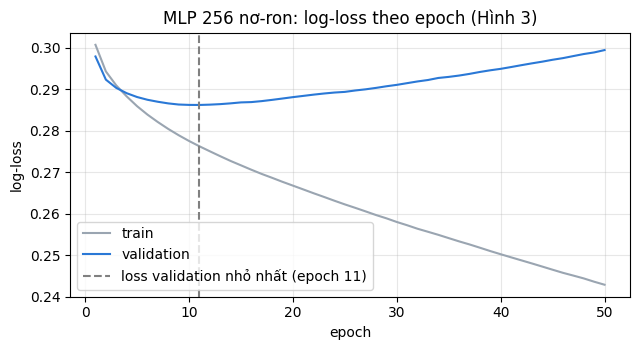

In [9]:
# [TỰ KIỂM TRA]
assert len(bang_epoch) == SO_EPOCH and bang_epoch["loss_val"].notna().all(), "CHƯA ĐẠT: cần loss validation cho mỗi epoch."
assert len(mlp_epoch.loss_curve_) == SO_EPOCH, "CHƯA ĐẠT: mỗi vòng lặp phải huấn luyện thêm đúng một epoch (chạy lại từ ô tạo mlp_epoch)."
epoch_tot = int(bang_epoch.loc[bang_epoch["loss_val"].idxmin(), "epoch"])
print("ĐẠT: loss validation nhỏ nhất ở epoch", epoch_tot)
display(bang_epoch.iloc[[0, 4, 9, 19, 29, 39, 49]].round(4).set_index("epoch").T)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(bang_epoch["epoch"], bang_epoch["loss_train"], color="#9aa5b1", label="train")
ax.plot(bang_epoch["epoch"], bang_epoch["loss_val"], color="#2a78d6", label="validation")
ax.axvline(epoch_tot, color="gray", linestyle="--", label=f"loss validation nhỏ nhất (epoch {epoch_tot})")
ax.set_xlabel("epoch"); ax.set_ylabel("log-loss"); ax.set_title("MLP 256 nơ-ron: log-loss theo epoch (Hình 3)")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

`[KIẾN THỨC]` **Dừng sớm** (*early stopping*). Không biết trước nên dừng ở epoch nào, nên `MLPClassifier(early_stopping=True)` tự làm việc này: tách ngẫu nhiên **10% của train** làm tập kiểm tra nội bộ, sau mỗi epoch đo Accuracy trên phần này, dừng khi 10 epoch liên tiếp không cải thiện, rồi giữ lại trọng số của epoch tốt nhất. Số epoch đã chạy nằm trong thuộc tính `n_iter_`. Tập validation của đồ án **không** được dùng ở bước này, nên vẫn là dữ liệu chưa thấy để so sánh mô hình.

`[CÂU HỎI SUY NGẪM]` (Câu 1) Vì sao loss trên train giảm gần như mãi, còn loss trên validation thì không? Nếu báo cáo mô hình ở epoch 50, người đọc sẽ hiểu sai điều gì?

Trả lời: Loss trên train giảm từ 0,3007 xuống 0,2429 vì mô hình ngày càng học tốt dữ liệu huấn luyện. Tuy nhiên, loss trên validation thấp nhất ở epoch 11 rồi tăng trở lại, đến epoch 50 là 0,2995. Đây là dấu hiệu của hiện tượng quá khớp, khi mô hình học quá nhiều những đặc điểm riêng của train. Nếu chỉ báo cáo ở epoch 50, người đọc có thể hiểu nhầm rằng huấn luyện càng lâu thì mô hình càng tốt, trong khi khả năng dự đoán trên dữ liệu mới đã giảm.

`[BÁO CÁO]` Chép Hình 3; ghi epoch có loss validation nhỏ nhất; giải thích đường cong trong 2–3 câu, dùng từ *quá khớp*; một câu về việc dừng sớm dùng phần dữ liệu nào.

*Trả lời của sinh viên:*
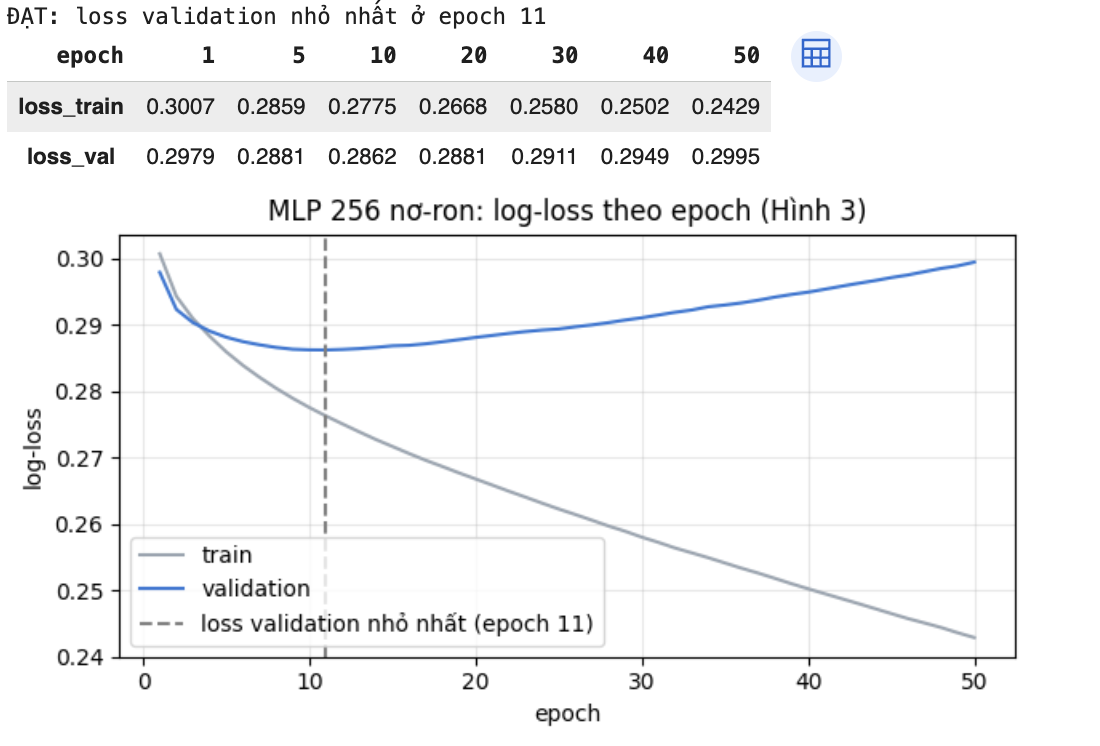Loss trên validation đạt giá trị nhỏ nhất tại epoch [...]. Trong quá trình huấn luyện, loss trên train nhìn chung tiếp tục giảm, còn loss trên validation có thể tăng trở lại sau một số epoch. Điều này cho thấy mô hình bắt đầu quá khớp, nên không phải cứ huấn luyện đủ 50 epoch là cho kết quả tốt nhất.

Khi sử dụng early_stopping=True, MLP lấy 10% dữ liệu train làm tập kiểm tra nội bộ để quyết định thời điểm dừng, không sử dụng tập validation chính của đồ án.

## 3.3 `[KIẾN THỨC]` Ngưỡng quyết định và so sánh công bằng
`predict` dự đoán `yes` khi xác suất `yes` ≥ 0,5. Với xác suất `p_yes` của mỗi khách (lấy bằng `predict_proba`) và một ngưỡng τ (tau): **dự đoán yes khi `p_yes` ≥ τ**.
- hạ τ → chọn nhiều khách để gọi hơn → Recall-yes tăng, Precision-yes thường giảm;
- tăng τ → chọn ít khách hơn → ngược lại.

E1 dùng `class_weight="balanced"` nên xác suất `yes` bị đẩy lên; `MLPClassifier` và kNN **không** có tham số `class_weight`, nên xác suất `yes` của chúng thường thấp và ở ngưỡng 0,5 chúng chọn rất ít khách. So sánh mọi mô hình ở cùng ngưỡng 0,5 vì vậy **thiên vị** mô hình có trọng số lớp. Quy tắc công bằng của đồ án: **mỗi mô hình dùng ngưỡng tốt nhất của chính nó trên validation**, trong 9 giá trị 0,1; 0,2; …; 0,9; nếu F1-yes bằng nhau, chọn ngưỡng gần 0,5 hơn.

`[MINH HỌA]` Hàm `f1_toi_uu` thực hiện quy tắc trên và được dùng cho **mọi** mô hình từ đây.

In [10]:
NGUONG = np.arange(1, 10) / 10

def f1_toi_uu(mo_hinh, du_lieu=val):
    """F1-yes lớn nhất trên du_lieu khi thử 9 ngưỡng; trả về (F1-yes, ngưỡng). Bằng nhau: chọn ngưỡng gần 0,5 hơn."""
    p = mo_hinh.predict_proba(du_lieu)[:, list(mo_hinh.classes_).index("yes")]
    f1 = [f1_score(du_lieu["y"], np.where(p >= t, "yes", "no"), pos_label="yes") for t in NGUONG]
    bang_f1 = pd.DataFrame({"tau": NGUONG, "f1": f1, "kc": np.abs(NGUONG - 0.5).round(2)})
    dong_tot = bang_f1.sort_values(["f1", "kc"], ascending=[False, True]).iloc[0]
    return float(dong_tot["f1"]), float(dong_tot["tau"])

pd.DataFrame({ten: {"F1-yes ở ngưỡng 0,5": f1_score(val["y"], m.predict(val), pos_label="yes"),
                    "F1-yes ở ngưỡng tốt nhất": f1_toi_uu(m)[0], "ngưỡng tốt nhất": f1_toi_uu(m)[1]}
              for ten, m in [("E1 hồi quy logistic", e1), ("E2 kNN (k = 15)", e2)]}).T.round(3)

,"F1-yes ở ngưỡng 0,5",F1-yes ở ngưỡng tốt nhất,ngưỡng tốt nhất
E1 hồi quy logistic,0.375,0.446,0.6
E2 kNN (k = 15),0.267,0.412,0.2


`[CÂU HỎI SUY NGẪM]` (Câu 2) Ở ngưỡng 0,5, E2 (kNN) kém E1 khá xa; ở ngưỡng tốt nhất của mỗi mô hình, khoảng cách thu hẹp. Vì sao? Ngưỡng tốt nhất của E1 cao hơn 0,5, còn của E2 thấp hơn 0,5: điều này liên quan gì đến trọng số lớp?

Trả lời: Ở ngưỡng 0,5, E1 đạt F1-yes là 0,375 còn E2 là 0,267, chênh lệch 0,108. Khi chọn ngưỡng tốt nhất, E1 đạt 0,446 tại ngưỡng 0,6 và E2 đạt 0,412 tại ngưỡng 0,2, khiến khoảng cách giảm còn 0,034. Nguyên nhân là E1 có sử dụng class_weight="balanced" để tăng trọng số cho lớp yes, nên ngưỡng tốt nhất cao hơn 0,5 để hạn chế dự đoán nhầm. Ngược lại, E2 không sử dụng trọng số lớp nên cần giảm ngưỡng xuống 0,2 để phát hiện thêm khách hàng đồng ý, cải thiện Recall và F1-yes.

## 3.4 `[YÊU CẦU]` E3: chọn số nơ-ron ẩn, có tính đến dao động theo seed
Trọng số của MLP được **khởi tạo ngẫu nhiên** (và dừng sớm tách 10% train ngẫu nhiên), nên cùng một cấu hình nhưng khác `random_state` (seed) sẽ cho kết quả khác. Chọn $H$ dựa trên **một** lần chạy có thể chỉ là chọn trúng một seed may mắn. Vì vậy mỗi $H \in \{4, 16, 64, 256\}$ được huấn luyện với **5 seed** (42 đến 46), có dừng sớm, và so sánh theo **trung bình**.

Yêu cầu sinh viên thực hiện, trong vòng lặp: (1) huấn luyện `mlp` trên train; (2) tính `f1_val, tau` bằng `f1_toi_uu(mlp)` (khoảng 1 phút).

In [11]:
SO_NO_RON = [4, 16, 64, 256]
SEED = [42, 43, 44, 45, 46]

def tao_mlp(H, seed):
    """MLP một lớp ẩn H nơ-ron, có dừng sớm; dùng chung bộ tiền xử lý với E1."""
    return make_pipeline(tao_tien_xu_ly(), MLPClassifier(hidden_layer_sizes=(H,), early_stopping=True, max_iter=300, random_state=seed))

In [12]:
dong = []
for H in SO_NO_RON:
    for seed in SEED:
        mlp = tao_mlp(H, seed)
        mlp.fit(train, train["y"])                    # YÊU CẦU (1): huấn luyện mlp trên train
        f1_val, tau = f1_toi_uu(mlp) # YÊU CẦU (2): f1_toi_uu(mlp)
        dong.append({"so_no_ron": H, "seed": seed, "f1_val": f1_val, "tau": tau, "so_epoch": mlp[-1].n_iter_})
bang_mlp = pd.DataFrame(dong)
bang_mlp.pivot(index="so_no_ron", columns="seed", values="f1_val").round(3)

seed,42,43,44,45,46
so_no_ron,,,,,
4,0.461,0.443,0.446,0.379,0.443
16,0.462,0.459,0.471,0.439,0.471
64,0.470,0.446,0.450,0.475,0.459
256,0.476,0.490,0.470,0.488,0.491


`[MINH HỌA]` Chọn số nơ-ron theo quy tắc cố định: **trung bình** F1-yes trên validation (qua 5 seed) lớn nhất; nếu bằng nhau, chọn mạng **nhỏ hơn**. Mô hình E3 dùng số nơ-ron đã chọn với **seed 42**, cố định từ trước, không chọn seed cho điểm cao nhất. Bảng tổng hợp dùng cho **Bảng 12**, biểu đồ dùng làm **Hình 4** của báo cáo.

ĐẠT: số nơ-ron được chọn = 256 | E3 (seed 42): F1-yes validation = 0.476 tại ngưỡng 0.2


,f1_tb,do_lech_chuan,f1_min,f1_max,so_epoch_tb,so_tham_so
so_no_ron,,,,,,
4,0.434,0.032,0.379,0.461,20.2,209
16,0.460,0.013,0.439,0.471,20.2,833
64,0.460,0.013,0.446,0.475,14.8,3329
256,0.483,0.009,0.470,0.491,20.0,13313


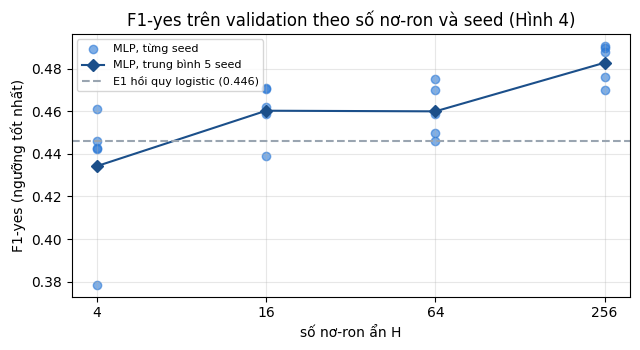

In [13]:
assert len(bang_mlp) == 20 and bang_mlp["f1_val"].notna().all(), "CHƯA ĐẠT: cần đủ 4 x 5 lần huấn luyện và F1-yes trên validation."
so_dac_trung = len(tao_tien_xu_ly().fit(train).get_feature_names_out())
tong_hop = bang_mlp.groupby("so_no_ron").agg(f1_tb=("f1_val", "mean"), do_lech_chuan=("f1_val", "std"), f1_min=("f1_val", "min"),
                                              f1_max=("f1_val", "max"), so_epoch_tb=("so_epoch", "mean"))
tong_hop["so_tham_so"] = [so_dac_trung * H + 2 * H + 1 for H in tong_hop.index]
so_no_ron_tot = int(tong_hop["f1_tb"].idxmax())       # khi bằng nhau, idxmax giữ mạng nhỏ hơn (đứng trước)
e3 = tao_mlp(so_no_ron_tot, 42).fit(train, train["y"])
f1_e3, tau_e3 = f1_toi_uu(e3)
f1_e1, tau_e1 = f1_toi_uu(e1)
print(f"ĐẠT: số nơ-ron được chọn = {so_no_ron_tot} | E3 (seed 42): F1-yes validation = {f1_e3:.3f} tại ngưỡng {tau_e3}")
display(tong_hop.round(3))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
vi_tri = {H: i for i, H in enumerate(SO_NO_RON)}
ax.scatter(bang_mlp["so_no_ron"].map(vi_tri), bang_mlp["f1_val"], color="#2a78d6", alpha=0.6, label="MLP, từng seed")
ax.plot(range(len(SO_NO_RON)), tong_hop["f1_tb"], "D-", color="#1b4f8a", label="MLP, trung bình 5 seed")
ax.axhline(f1_e1, color="#9aa5b1", linestyle="--", label=f"E1 hồi quy logistic ({f1_e1:.3f})")
ax.set_xticks(range(len(SO_NO_RON)), [str(H) for H in SO_NO_RON])
ax.set_xlabel("số nơ-ron ẩn H"); ax.set_ylabel("F1-yes (ngưỡng tốt nhất)"); ax.set_title("F1-yes trên validation theo số nơ-ron và seed (Hình 4)")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

`[CÂU HỎI SUY NGẪM]` (Câu 3) Trong bảng có một seed cho F1-yes cao nhất. Vì sao **không** chọn seed đó làm mô hình E3? Độ lệch chuẩn theo seed cho biết điều gì khi so sánh E3 với E1?

Trả lời: Trong bảng kết quả, MLP 256 nơ-ron với seed 46 đạt F1-yes cao nhất là 0,491. Tuy nhiên, em không chọn seed này vì kết quả cao có thể đến từ sự khởi tạo ngẫu nhiên. Thay vào đó, em chọn số nơ-ron dựa trên F1-yes trung bình của năm seed rồi sử dụng seed 42 đã được cố định từ trước. MLP 256 nơ-ron có F1-yes trung bình là 0,483 và độ lệch chuẩn 0,009, cho thấy kết quả tương đối ổn định giữa các lần chạy. Độ lệch chuẩn giúp đánh giá mức dao động do seed; nếu chênh lệch giữa hai mô hình quá nhỏ so với mức dao động này thì chưa thể kết luận mô hình nào thực sự tốt hơn.

`[BÁO CÁO]` Chép Bảng 12 và Hình 4; ghi số nơ-ron được chọn; so sánh trong 2–3 câu: (a) chênh lệch giữa các $H$ so với độ lệch chuẩn theo seed; (b) khoảng cách giữa MLP và E1 so với độ lệch chuẩn theo seed.

*Trả lời của sinh viên:*
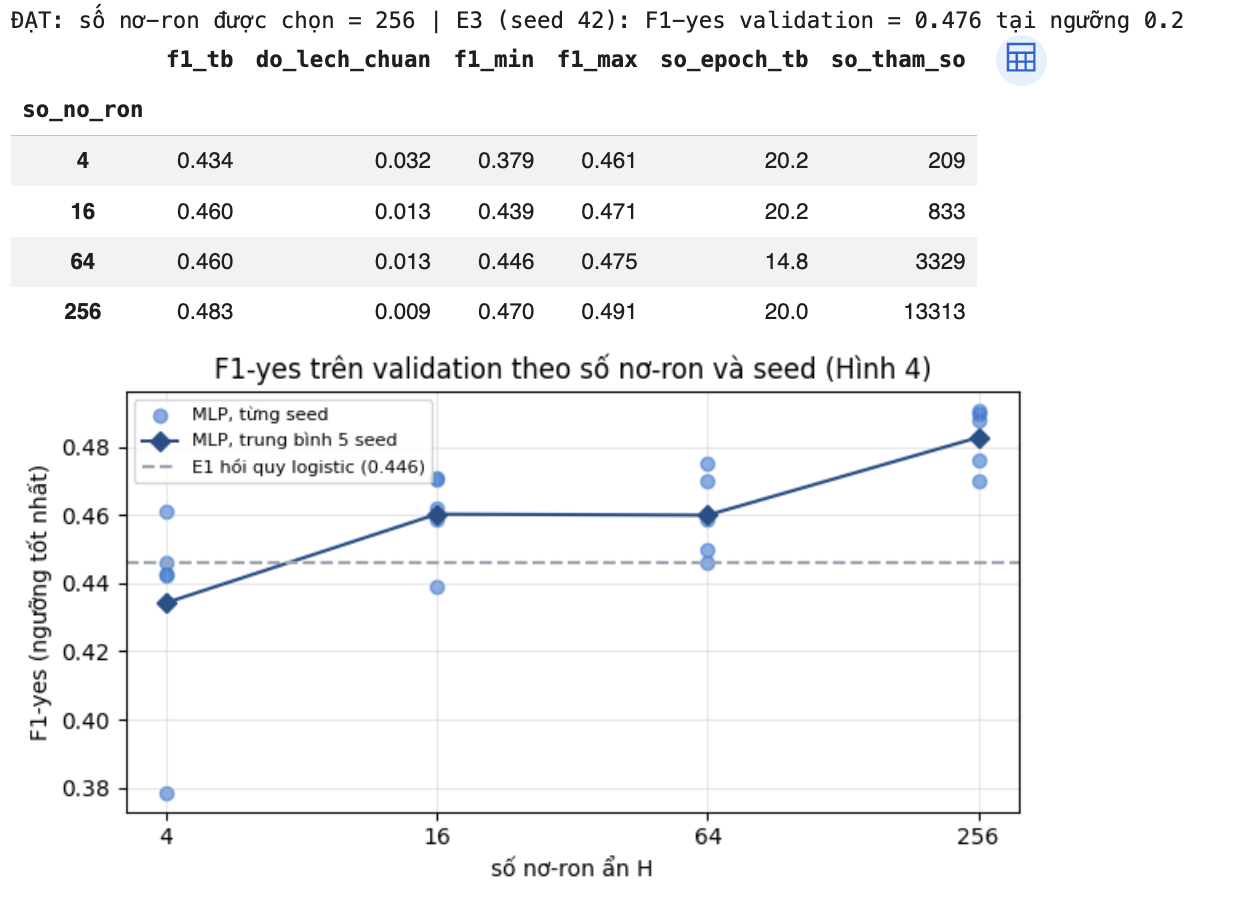
Em chọn MLP có 256 nơ-ron ẩn vì đạt F1-yes trung bình cao nhất là 0,483, với độ lệch chuẩn thấp nhất là 0,009. Hai cấu hình 16 và 64 nơ-ron đều đạt trung bình khoảng 0,460, trong khi cấu hình 4 nơ-ron thấp hơn và có độ dao động lớn nhất. So với cấu hình 64 nơ-ron, MLP 256 nơ-ron cao hơn 0,023 điểm F1, lớn hơn độ lệch chuẩn của hai cấu hình này (0,009 và 0,013). MLP 256 nơ-ron cũng cao hơn E1 (0,446) khoảng 0,037 điểm F1 trung bình, cho thấy kết quả tốt hơn trong các lần thử hiện tại, dù vẫn cần kiểm tra trên test. E3 chính thức được huấn luyện với 256 nơ-ron và seed 42, đạt F1-yes = 0,476 trên validation tại ngưỡng 0,2.



## 3.5 `[KIẾN THỨC]` Giả thuyết và lý do phải viết trước
Một giả thuyết gồm ba phần: **cơ chế** (vì sao thay đổi có thể giúp ích), **dự đoán** (kết quả quan sát được), **điều kiện bác bỏ** (khi nào giả thuyết sai). Giả thuyết viết sau khi đã biết kết quả có thể được diễn giải sao cho khớp với bất kỳ kết quả nào.

Mục 3.1 cho thấy MLP có thể **tự học** dạng chữ U của tuổi nhờ lớp ẩn. Cải tiến E4 thử cách **thủ công** với hồi quy logistic: thêm thuộc tính phân loại `nhom_tuoi` (các mốc 25, 30, 40, 50, 60) vào E1, để mỗi nhóm tuổi có hệ số riêng.

`[BÁO CÁO]` **Yêu cầu sinh viên viết giả thuyết TRƯỚC khi chạy mục 3.6** (sửa trực tiếp ô này):
- *Ngày viết:* 17/11/2026
- *Cơ chế:* Ở Tuần 1, tỷ lệ đồng ý giữa các nhóm tuổi có sự khác biệt khá rõ. Việc bổ sung thuộc tính nhom_tuoi có thể giúp Logistic Regression nhận biết sự khác biệt này tốt hơn so với chỉ sử dụng tuổi dạng số.
- *Dự đoán:* F1-yes (ở ngưỡng tốt nhất) trên validation của E4 cao hơn so với E1.
- *Giả thuyết bị bác bỏ khi:* F1-yes tốt nhất của E4 nhỏ hơn hoặc bằng E1 trên validation.
- *Nhận xét kết quả:* E4 đạt F1-yes tốt nhất là 0,458 tại ngưỡng 0,7, cao hơn E1 là 0,446 tại ngưỡng 0,6, chênh lệch 0,012. Kết quả phù hợp với dự đoán E4 có thể tốt hơn E1, nhưng mức cải thiện khá nhỏ nên chưa đủ để khẳng định việc thêm nhóm tuổi chắc chắn hiệu quả trên dữ liệu mới.

So với E1, E4 cải thiện 0,012 điểm F1, còn E3 đạt 0,476 và cải thiện 0,030 điểm. Như vậy, trong lần thực nghiệm này, MLP tự học E3 cải thiện nhiều hơn so với cách thêm nhóm tuổi thủ công E4.

## 3.6 `[YÊU CẦU]` E4: hồi quy logistic thêm nhóm tuổi
Hàm `them_nhom_tuoi` thêm cột `nhom_tuoi`; `FunctionTransformer` đưa hàm này vào pipeline. Yêu cầu sinh viên thực hiện: dựng pipeline `e4` gồm ba bước `FunctionTransformer(them_nhom_tuoi)`, `tao_tien_xu_ly(["nhom_tuoi"])` và `LogisticRegression(max_iter=1000, class_weight="balanced")`; huấn luyện trên train; tính `f1_e4, tau_e4` bằng `f1_toi_uu`.

In [14]:
from sklearn.preprocessing import FunctionTransformer

def them_nhom_tuoi(df):
    """Thêm cột nhom_tuoi theo các mốc cố định (không học từ dữ liệu nên không gây rò rỉ)."""
    return df.assign(nhom_tuoi=pd.cut(df["age"], [0, 25, 30, 40, 50, 60, 200]).astype(str))

them_nhom_tuoi(train.head(3))[["age", "nhom_tuoi"]]

,age,nhom_tuoi
0,43,"(40, 50]"
1,40,"(30, 40]"
2,39,"(30, 40]"


In [15]:
e4 = make_pipeline(FunctionTransformer(them_nhom_tuoi), tao_tien_xu_ly(["nhom_tuoi"]),
                   LogisticRegression(max_iter=1000, class_weight="balanced")).fit(train, train["y"])         # YÊU CẦU: make_pipeline(ba bước).fit(train, train["y"])
f1_e4, tau_e4 = f1_toi_uu(e4)  # YÊU CẦU: f1_toi_uu(e4)

In [16]:
# [TỰ KIỂM TRA]
assert e4 is not None and f1_e4 is not None, "CHƯA ĐẠT: cần tạo e4 và tính f1_e4, tau_e4."
assert len(e4[-1].coef_[0]) == len(e1[-1].coef_[0]) + 6, "CHƯA ĐẠT: E4 phải có thêm 6 đặc trưng nhóm tuổi so với E1."
kq_e4 = chi_so(val["y"], e4.predict(val))
print("ĐẠT: E4 đã sẵn sàng. Số đặc trưng E1 / E4:", len(e1[-1].coef_[0]), "/", len(e4[-1].coef_[0]))
pd.DataFrame({"E1": {"F1-yes ở ngưỡng 0,5": kq_e1["f1_yes"], "F1-yes ở ngưỡng tốt nhất": f1_e1, "ngưỡng tốt nhất": tau_e1},
              "E4 (E1 + nhóm tuổi)": {"F1-yes ở ngưỡng 0,5": kq_e4["f1_yes"], "F1-yes ở ngưỡng tốt nhất": f1_e4, "ngưỡng tốt nhất": tau_e4}}).T.round(3)

ĐẠT: E4 đã sẵn sàng. Số đặc trưng E1 / E4: 50 / 56


,"F1-yes ở ngưỡng 0,5",F1-yes ở ngưỡng tốt nhất,ngưỡng tốt nhất
E1,0.375,0.446,0.6
E4 (E1 + nhóm tuổi),0.385,0.458,0.7


`[BÁO CÁO]` Kết quả có đúng như dự đoán trong giả thuyết không? Trả lời trong 1–2 câu, lưu ý rằng chênh lệch nhỏ trên validation chưa phải bằng chứng chắc chắn. So sánh thêm: cách thủ công (E4) và MLP tự học (E3), cách nào cải thiện so với E1 nhiều hơn?

*Trả lời của sinh viên:* Kết quả phù hợp với giả thuyết ban đầu khi E4 đạt F1-yes = 0,458, cao hơn E1 (0,446) là 0,012. Tuy nhiên, mức chênh lệch này khá nhỏ nên chưa đủ để khẳng định E4 sẽ tốt hơn trên dữ liệu mới. Trong khi đó, E3 (MLP) đạt F1-yes = 0,476, cải thiện 0,030 so với E1, cao hơn mức cải thiện 0,012 của E4. Như vậy, trong thí nghiệm này, MLP tự học (E3) cho kết quả cải thiện tốt hơn cách thêm nhóm tuổi thủ công (E4).

### 3.6b `[NÂNG CAO — không bắt buộc]` E5: rừng ngẫu nhiên
Rừng ngẫu nhiên (*random forest*) huấn luyện nhiều cây quyết định trên các mẫu ngẫu nhiên của train rồi lấy trung bình. Nếu thực hiện phần này, sinh viên viết thêm một giả thuyết ngắn (vì sao rừng có thể tốt hơn MLP hoặc hồi quy logistic), rồi bỏ dấu `#` ở ba dòng cuối. E5 sẽ được xét là một ứng viên ở mục 3.7.

In [17]:
from sklearn.ensemble import RandomForestClassifier
ung_vien_them = {}
# e5 = make_pipeline(tao_tien_xu_ly(), RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced",
#                                                             random_state=42, n_jobs=-1)).fit(train, train["y"])
# ung_vien_them["E5"] = e5

## 3.7 `[MINH HỌA]` Chọn mô hình
**Quy tắc (cố định trước):** ứng viên có F1-yes trên validation **ở ngưỡng tốt nhất của chính nó** lớn nhất; nếu bằng nhau, chọn mô hình đứng trước trong danh sách (đơn giản hơn). Cột "ở ngưỡng 0,5" được giữ để thấy thứ hạng thay đổi thế nào khi so sánh công bằng. Kết quả dùng cho **Bảng 13**.

In [18]:
ung_vien = {"E1": e1, "E2": e2, "E3": e3, "E4": e4, **ung_vien_them}
dong = []
for ten, m in ung_vien.items():
    f1_tot, tau_tot = f1_toi_uu(m)
    dong.append({"mo_hinh": ten, "f1_nguong_0_5": f1_score(val["y"], m.predict(val), pos_label="yes"), "f1_toi_uu": f1_tot, "nguong_toi_uu": tau_tot})
bang_chon = pd.DataFrame(dong).set_index("mo_hinh")
mo_hinh_chon = bang_chon["f1_toi_uu"].idxmax()      # khi bằng nhau, idxmax giữ ứng viên đứng trước
mo_hinh = ung_vien[mo_hinh_chon]
print("Mô hình được chọn:", mo_hinh_chon)
bang_chon.round(3)

Mô hình được chọn: E3


,f1_nguong_0_5,f1_toi_uu,nguong_toi_uu
mo_hinh,,,
E1,0.375,0.446,0.6
E2,0.267,0.412,0.2
E3,0.352,0.476,0.2
E4,0.385,0.458,0.7


`[CÂU HỎI SUY NGẪM]` (Câu 4) Nếu chọn mô hình theo cột "ở ngưỡng 0,5", mô hình nào được chọn? Vì sao kết luận đó không công bằng với MLP?

Trả lời: Nếu chỉ xét F1-yes ở ngưỡng 0,5, mô hình được chọn là E4 với F1-yes = 0,385, cao hơn E1 (0,375), E3 (0,352) và E2 (0,267). Tuy nhiên, cách so sánh này chưa công bằng với MLP vì E1 và E4 có sử dụng trọng số lớp, còn MLP không có. Khi điều chỉnh ngưỡng riêng cho từng mô hình, E3 tăng F1-yes từ 0,352 lên 0,476 và trở thành mô hình tốt nhất. Vì vậy, chỉ sử dụng ngưỡng 0,5 có thể khiến chúng ta đánh giá thấp khả năng của MLP.

## 3.8 `[YÊU CẦU]` Bảng ngưỡng của mô hình đã chọn
Yêu cầu sinh viên thực hiện cho mô hình đã chọn:
1. tính `p_val`: xác suất `yes` trên validation, `mo_hinh.predict_proba(val)[:, cot_yes]` (cột được xác định theo `mo_hinh.classes_`);
2. hoàn thành vòng lặp tính Precision, Recall, F1 của lớp yes tại mỗi ngưỡng bằng `precision_recall_fscore_support`.

In [19]:
cot_yes = list(mo_hinh.classes_).index("yes")
p_val = mo_hinh.predict_proba(val)[:, cot_yes]        # YÊU CẦU: bước 1
dong = []
for tau in NGUONG:
    y_tau = np.where(p_val >= tau, "yes", "no")
    p, r, f, _ = precision_recall_fscore_support(val["y"], y_tau, labels=["yes"], zero_division=0)     # YÊU CẦU: precision_recall_fscore_support(val["y"], y_tau, labels=["yes"], zero_division=0)
    dong.append({"tau": tau, "precision_yes": p[0], "recall_yes": r[0], "f1_yes": f[0], "so_cuoc_goi": int((y_tau == "yes").sum())})
bang = pd.DataFrame(dong)
bang.round(3)

,tau,precision_yes,recall_yes,f1_yes,so_cuoc_goi
0,0.1,0.247,0.730,0.369,3124
1,0.2,0.428,0.537,0.476,1328
2,0.3,0.518,0.435,0.473,888
3,0.4,0.583,0.348,0.436,631
4,0.5,0.639,0.243,0.352,402
5,0.6,0.690,0.162,0.262,248
6,0.7,0.692,0.102,0.178,156
7,0.8,0.747,0.053,0.099,75
8,0.9,1.000,0.001,0.002,1


`[MINH HỌA]` Chọn τ\* theo quy tắc của mục 3.3; τ\* phải trùng với ngưỡng tốt nhất của mô hình đã chọn trong Bảng 13. Bảng ngưỡng dùng cho **Bảng 14**, biểu đồ dùng làm **Hình 5** của báo cáo.

ĐẠT: tau* = 0.2


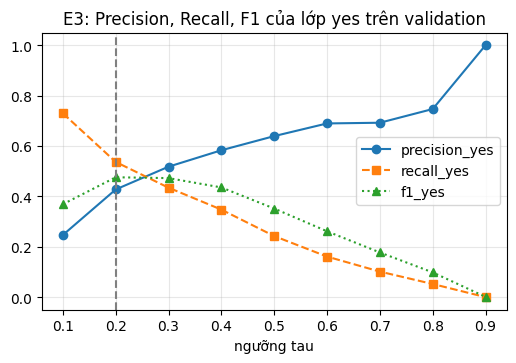

In [20]:
thu_tu = bang.assign(_f1=bang["f1_yes"], _kc=(bang["tau"] - 0.5).abs())
tau_sao = float(thu_tu.sort_values(["_f1", "_kc"], ascending=[False, True]).iloc[0]["tau"])
assert len(bang) == 9 and len(p_val) == len(val), "CHƯA ĐẠT: bảng phải có 9 ngưỡng và được tính trên validation."
assert tau_sao == bang_chon.loc[mo_hinh_chon, "nguong_toi_uu"], "CHƯA ĐẠT: tau* phải trùng ngưỡng tốt nhất ở Bảng 13."
print("ĐẠT: tau* =", tau_sao)
ax = bang.plot(x="tau", y=["precision_yes", "recall_yes", "f1_yes"], style=["o-", "s--", "^:"], figsize=(6, 3.6),
               title=f"{mo_hinh_chon}: Precision, Recall, F1 của lớp yes trên validation")
ax.axvline(tau_sao, color="gray", linestyle="--"); ax.set_xlabel("ngưỡng tau"); ax.grid(alpha=0.3); plt.show()

`[CÂU HỎI SUY NGẪM]` (Câu 5) F1-yes tốt nhất trong bảng có phải là hiệu năng có thể kỳ vọng với khách hàng mới không? Vì sao con số này được xem là "lạc quan"?

Trả lời: Không thể khẳng định F1-yes = 0,4761 sẽ đạt được với khách hàng mới. Vì số nơ-ron, mô hình và ngưỡng đều được lựa chọn dựa trên kết quả validation nên điểm số này có thể chịu ảnh hưởng từ những đặc điểm riêng của tập dữ liệu đó. Do đó, kết quả có thể lạc quan hơn khả năng dự đoán thực tế. Cần đánh giá trên tập test chưa sử dụng để kiểm tra lại hiệu năng.

`[BÁO CÁO]` Chép Bảng 13 (các ứng viên ở hai cách so sánh) và Bảng 14; giải thích trong 2 câu: khi hạ hoặc tăng ngưỡng so với τ\*, số cuộc gọi, Precision-yes và Recall-yes thay đổi như thế nào.

*Trả lời của sinh viên:*

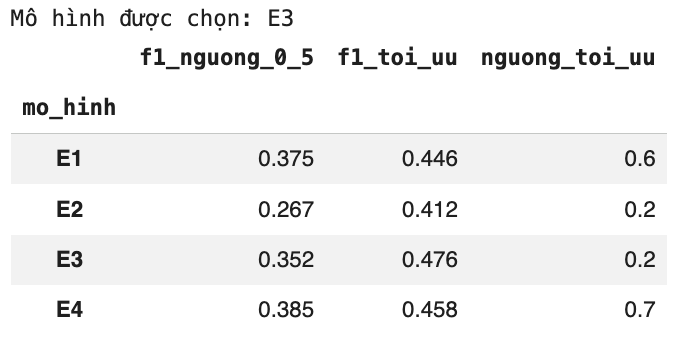

Khi so sánh ở ngưỡng 0,5, E4 đứng đầu với F1-yes = 0,385. Tuy nhiên, khi mỗi mô hình được sử dụng ngưỡng tốt nhất, E3 đạt F1-yes cao nhất là 0,476. Vì vậy, em chọn E3 để tiếp tục đánh giá.

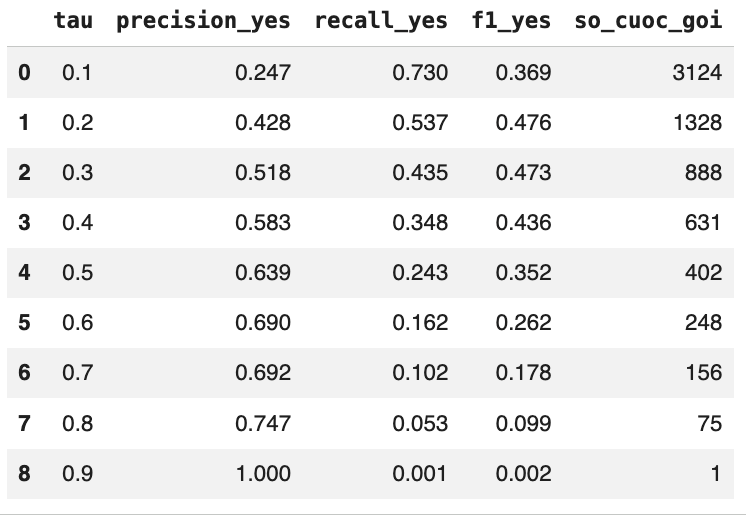

Ngưỡng được chọn là τ = 0,2*, với F1-yes = 0,476, Precision-yes = 0,428 và Recall-yes = 0,537; tại ngưỡng này có 1.328 khách hàng trong tập validation được dự đoán yes. Khi giảm ngưỡng xuống 0,1, số khách được chọn tăng lên 3.124 và Recall-yes tăng lên 0,730, nhưng Precision-yes giảm còn 0,247. Ngược lại, khi tăng ngưỡng lên 0,3, số khách được chọn giảm còn 888, Precision-yes tăng lên 0,518 nhưng Recall-yes giảm xuống 0,435.

## 3.9 `[YÊU CẦU]` Khóa quyết định
Ô dưới đây in ra **một dòng quyết định**. Yêu cầu sinh viên **chép nguyên dòng này** vào báo cáo và vào notebook tuần 4.
Từ thời điểm này, **không thay đổi mô hình, số nơ-ron và ngưỡng**, bất kể kết quả trên test.

In [21]:
QUYET_DINH = {"mssv": MSSV, "mo_hinh": mo_hinh_chon, "so_no_ron": so_no_ron_tot, "nguong": tau_sao,
              "f1_yes_val": round(float(bang.loc[bang["tau"] == tau_sao, "f1_yes"].iloc[0]), 4),   # YÊU CẦU: F1-yes tại dòng tau* của bảng, làm tròn 4 chữ số
              "thoi_diem": datetime.datetime.now().strftime("%Y-%m-%d %H:%M")}
print(json.dumps(QUYET_DINH, ensure_ascii=False))

{"mssv": "3124411079", "mo_hinh": "E3", "so_no_ron": 256, "nguong": 0.2, "f1_yes_val": 0.4761, "thoi_diem": "2026-11-17 02:51"}


In [22]:
# [TỰ KIỂM TRA]
assert isinstance(QUYET_DINH["f1_yes_val"], float) and 0 < QUYET_DINH["f1_yes_val"] <= 1, "CHƯA ĐẠT: cần điền F1-yes validation tại tau*."
print("ĐẠT: quyết định đã khóa; chép dòng in ra ở ô trên.")

ĐẠT: quyết định đã khóa; chép dòng in ra ở ô trên.


## Nộp cuối tuần 3
- [x] Bài luyện tập tính tay (mục 3.1) khớp scikit-learn.
- [x] Giả thuyết E4 có ngày viết và được viết trước khi chạy.
- [x] Đã có Hình 3 (loss theo epoch), Bảng 12 và Hình 4 (số nơ-ron, 5 seed), Bảng 13 (E1–E4, và E5 nếu thực hiện), Bảng 14 và τ\*.
- [x] Dòng `QUYET_DINH` đã được chép vào báo cáo.
- [x] **Viết nháp báo cáo:** Mục 3.6–3.7, Mục 4 (Bảng 12–14, Hình 3–5); dòng tuần 3 của Phụ lục A; Hình B.3.
- [x] Tải notebook đã chạy (*File → Download → Download .ipynb*), đặt tên `MSSV_tuan3.ipynb` và **lưu lại**: cả bốn notebook được nộp một lần cùng báo cáo vào cuối tuần 4 (không có đợt nộp giữa kỳ). Notebook tuần 3 phải có dòng `QUYET_DINH`; chép dòng này vào báo cáo ngay khi khóa, trước khi mở notebook tuần 4.

---
### Gợi ý trả lời các câu hỏi suy ngẫm
<details><summary>Mở phần này sau khi đã tự trả lời</summary>

**Câu 1.** Trên train, mỗi epoch đều điều chỉnh trọng số để khớp chính các khách này hơn, nên loss train gần như luôn giảm. Sau một số epoch, mạng bắt đầu ghi nhớ chi tiết riêng (kể cả nhiễu) của train: loss validation dừng giảm rồi tăng, đó là quá khớp. Báo cáo mô hình ở epoch 50 là báo cáo một mô hình dự đoán khách mới kém hơn mô hình ở epoch có loss validation nhỏ nhất; dừng sớm giải quyết việc này mà không cần dùng tập validation của đồ án.

**Câu 2.** kNN và MLP không có trọng số lớp nên xác suất yes của chúng thấp; ở ngưỡng 0,5 chúng chọn rất ít khách (Recall thấp). E1 có trọng số lớp, xác suất yes bị đẩy lên, nên ngưỡng tốt nhất của E1 cao hơn 0,5, còn của kNN thấp hơn 0,5. So ở cùng ngưỡng 0,5 là so một mô hình đã được "hiệu chỉnh" cho lớp hiếm với một mô hình chưa được hiệu chỉnh.

**Câu 3.** Seed chỉ quyết định khởi tạo ngẫu nhiên, không phải đặc điểm của mô hình; chọn seed tốt nhất trên validation là chọn trúng may rủi, điểm đó sẽ không lặp lại với khách mới (lạc quan do lựa chọn). Độ lệch chuẩn theo seed là thước đo nhiễu: một chênh lệch giữa hai mô hình nhỏ hơn hoặc xấp xỉ mức này chưa đủ để kết luận mô hình nào tốt hơn.

**Câu 4.** Ở ngưỡng 0,5, E4 hoặc E1 (có trọng số lớp) đứng đầu, còn MLP chịu thiệt vì xác suất yes của MLP thấp. Kết luận "hồi quy logistic tốt hơn MLP" khi đó chỉ phản ánh việc MLP chưa được chọn ngưỡng, không phản ánh khả năng xếp hạng khách của MLP.

**Câu 5.** Không. Số nơ-ron, mô hình và ngưỡng đều được chọn vì cho điểm cao nhất trên validation, nên một phần điểm cao đến từ việc "chọn trúng" các dao động ngẫu nhiên của tập này. Hiệu năng với khách hàng mới thường thấp hơn một chút; vì vậy cần tập test chưa được sử dụng.
</details>